In [2]:
!pip install tqdm

  Using cached tqdm-4.70.0-py3-none-any.whl (80 kB)



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: C:\Users\okubo\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path
import glob
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from soja_clima.inmet import COLUNAS_CONHECIDAS, COLUNAS_ESSENCIAIS
from soja_clima.qualidade import FAIXAS_PLAUSIVEIS
from soja_clima.qualidade import diagnosticar_arquivo
from soja_clima.analise import mapa_estacoes_animado, plotar_serie_horaria

c:\Users\okubo\OneDrive\Documentos\PCD2\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
PASTA_RAIZ = "../data/raw/DadosClimaticos"

arquivos = sorted(set(
    glob.glob(f"{PASTA_RAIZ}/**/*.CSV", recursive=True) +
    glob.glob(f"{PASTA_RAIZ}/**/*.csv", recursive=True)
))

diagnosticos, erros_diag = [], []
for path in tqdm(arquivos, desc="Diagnosticando"):
    try:
        diagnosticos.append(diagnosticar_arquivo(path))
    except Exception as e:
        erros_diag.append((path, str(e)))

diag_df = pd.DataFrame(diagnosticos)
print(f"{len(diag_df)} arquivos diagnosticados, {len(erros_diag)} com erro.")

Diagnosticando: 100%|██████████| 9288/9288 [05:34<00:00, 27.77it/s]

9288 arquivos diagnosticados, 0 com erro.


In [5]:
diag_df['codigo_estacao'].nunique()

616

In [6]:
diag_df

,arquivo,codigo_estacao,estacao,uf,latitude,longitude,ano,n_horas,periodo_min,periodo_max,...,precipitacao_pct_faltante,umidade_pct_faltante,vento_pct_faltante,radiacao_pct_faltante,temperatura_fora_faixa,precipitacao_fora_faixa,umidade_fora_faixa,vento_fora_faixa,maior_gap_horas_temp,total_fora_faixa
0,DadosClimaticos\2005\2005\INMET_CO_DF_A001_BRA...,A001,BRASILIA,DF,-15.789444,-47.925833,2005,8760,2005-01-01,2005-12-31,...,2.4,2.4,2.4,20.7,0,0,0,0,5,0
1,DadosClimaticos\2005\2005\INMET_CO_GO_A002_GOI...,A002,GOIANIA,GO,-16.642778,-49.220000,2005,8760,2005-01-01,2005-12-31,...,15.8,15.8,15.8,9.5,0,0,0,0,489,0
2,DadosClimaticos\2005\2005\INMET_CO_GO_A003_MOR...,A003,MORRINHOS,GO,-17.716667,-49.100000,2005,8760,2005-01-01,2005-12-31,...,55.3,52.3,52.4,26.5,0,0,0,0,4168,0
3,DadosClimaticos\2005\2005\INMET_CO_MS_A702_CAM...,A702,CAMPO GRANDE,MS,-20.450000,-54.600000,2005,8760,2005-01-01,2005-12-31,...,9.5,9.4,9.5,9.1,0,0,0,0,113,0
4,DadosClimaticos\2005\2005\INMET_CO_MS_A703_PON...,A703,PONTA PORA,MS,-22.552500,-55.716389,2005,8760,2005-01-01,2005-12-31,...,72.9,74.2,72.9,34.3,0,0,0,0,5896,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9283,DadosClimaticos\2024\INMET_S_SC_A867_ARARANGUA...,A867,ARARANGUA,SC,-28.931353,-49.497920,2024,8784,2024-01-01,2024-12-31,...,0.0,5.3,0.0,2.9,0,0,0,0,0,0
9284,DadosClimaticos\2024\INMET_S_SC_A868_ITAJAI_01...,A868,ITAJAI,SC,-26.950833,-48.761944,2024,8784,2024-01-01,2024-12-31,...,1.0,1.0,1.0,1.8,0,0,0,0,46,0
9285,DadosClimaticos\2024\INMET_S_SC_A870_RANCHO QU...,A870,RANCHO QUEIMADO,SC,-27.678611,-49.041944,2024,8784,2024-01-01,2024-12-31,...,26.0,100.0,68.1,13.5,0,0,0,0,2248,0
9286,DadosClimaticos\2024\INMET_S_SC_A895_CHAPECO_0...,A895,CHAPECO,SC,-27.085311,-52.635711,2024,8784,2024-01-01,2024-12-31,...,2.0,65.2,2.0,4.1,0,0,0,0,4,0


In [7]:
print("\nTop 15 arquivos com mais dados faltando (temperatura):")
print(diag_df.sort_values('temperatura_pct_faltante', ascending=False)
      [['arquivo', 'codigo_estacao', 'ano', 'temperatura_pct_faltante']].head(15))

print("\nTop 15 arquivos com maior gap contínuo (horas seguidas sem dado):")
print(diag_df.sort_values('maior_gap_horas_temp', ascending=False)
      [['arquivo', 'codigo_estacao', 'ano', 'maior_gap_horas_temp']].head(15))

colunas_fora_faixa = [c for c in diag_df.columns if c.endswith('_fora_faixa')]
diag_df['total_fora_faixa'] = diag_df[colunas_fora_faixa].sum(axis=1)
print("\nTop 5 arquivos com mais valores fisicamente implausíveis:")
print(diag_df.sort_values('total_fora_faixa', ascending=False)
      [['arquivo', 'codigo_estacao', 'ano'] + colunas_fora_faixa].head(5))

# Completude por estação ao longo dos anos (útil para decidir se uma
# estação tem histórico bom o suficiente para entrar na agregação por UF)
print("\nCompletude média de temperatura por estação, todos os anos:")
print(diag_df.groupby('codigo_estacao')['temperatura_pct_faltante'].mean().sort_values(ascending=False))


Top 15 arquivos com mais dados faltando (temperatura):
                                                arquivo codigo_estacao   ano  \
3378  DadosClimaticos\2014\2014\INMET_NE_RN_A302_ARQ...           A302  2014   
3047  DadosClimaticos\2013\2013\INMET_SE_MG_F501_BEL...           F501  2013   
3433  DadosClimaticos\2014\2014\INMET_N_PA_A234_TUCU...           A234  2014   
941   DadosClimaticos\2009\2009\INMET_CO_MS_A752_ITA...           A752  2009   
7701  DadosClimaticos\2022\INMET_NE_BA_A412_MACAJUBA...           A412  2022   
7037  DadosClimaticos\2021\INMET_CO_MS_A717_NHUMIRIM...           A717  2021   
7049  DadosClimaticos\2021\INMET_CO_MS_A749_JUTI_01-...           A749  2021   
8385  DadosClimaticos\2023\INMET_NE_RN_A344_CALCANHA...           A344  2023   
7064  DadosClimaticos\2021\INMET_CO_MS_S705_BRASILAN...           S705  2021   
8325  DadosClimaticos\2023\INMET_NE_MA_A217_FAROL de...           A217  2023   
7067  DadosClimaticos\2021\INMET_CO_MS_S708_FATIMA D...         

In [7]:
(diag_df["temperatura_pct_faltante"] > 50).mean()*100

np.float64(9.808354866494401)

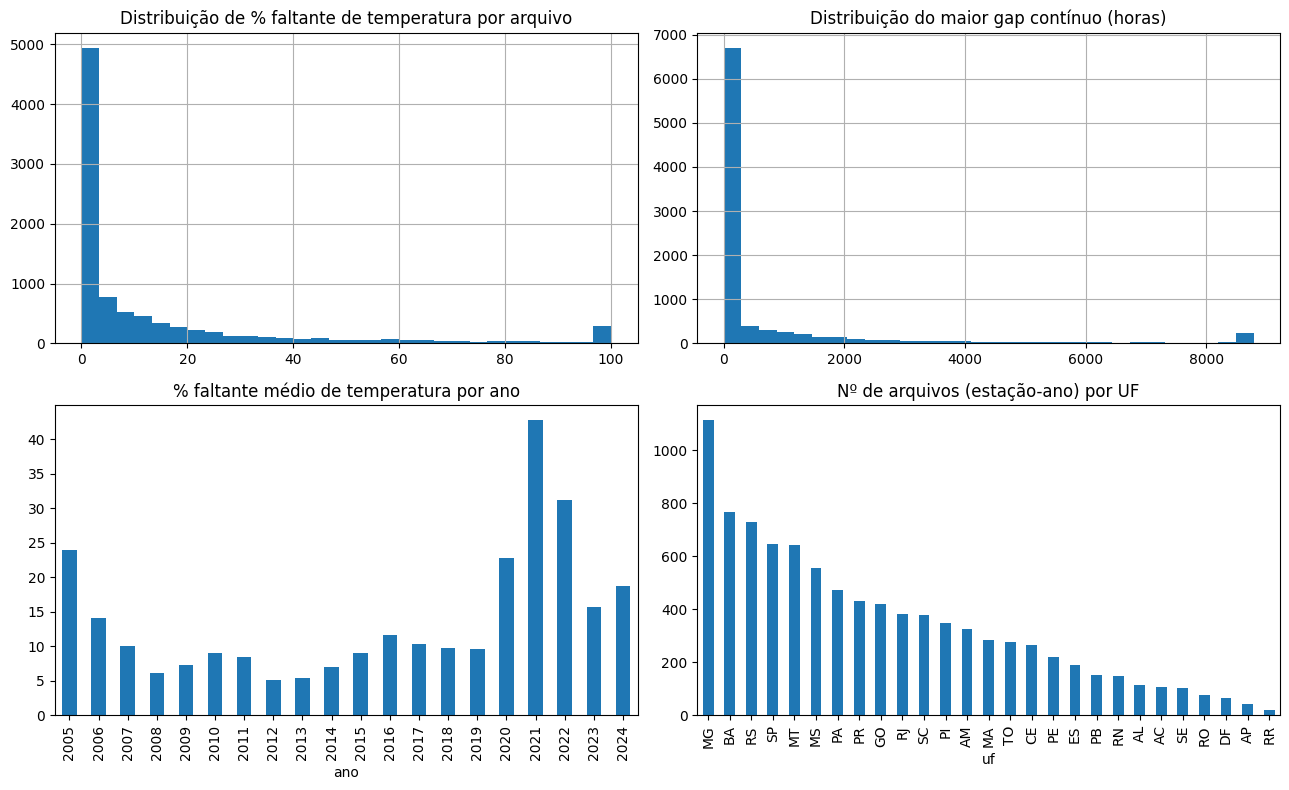

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

diag_df['temperatura_pct_faltante'].hist(bins=30, ax=axes[0, 0])
axes[0, 0].set_title('Distribuição de % faltante de temperatura por arquivo')

diag_df['maior_gap_horas_temp'].hist(bins=30, ax=axes[0, 1])
axes[0, 1].set_title('Distribuição do maior gap contínuo (horas)')

diag_df.groupby('ano')['temperatura_pct_faltante'].mean().plot(kind='bar', ax=axes[1, 0])
axes[1, 0].set_title('% faltante médio de temperatura por ano')

diag_df.groupby('uf')['n_horas'].count().sort_values(ascending=False).plot(kind='bar', ax=axes[1, 1])
axes[1, 1].set_title('Nº de arquivos (estação-ano) por UF')

plt.tight_layout()
plt.show()

In [ ]:
fig = mapa_estacoes_animado(
    arquivo=diag_df,
    col_estado="uf",
    col_ano="ano",
    col_estacao="codigo_estacao",
    ano_inicio=2005,
    ano_fim=2024,
)
fig.show()


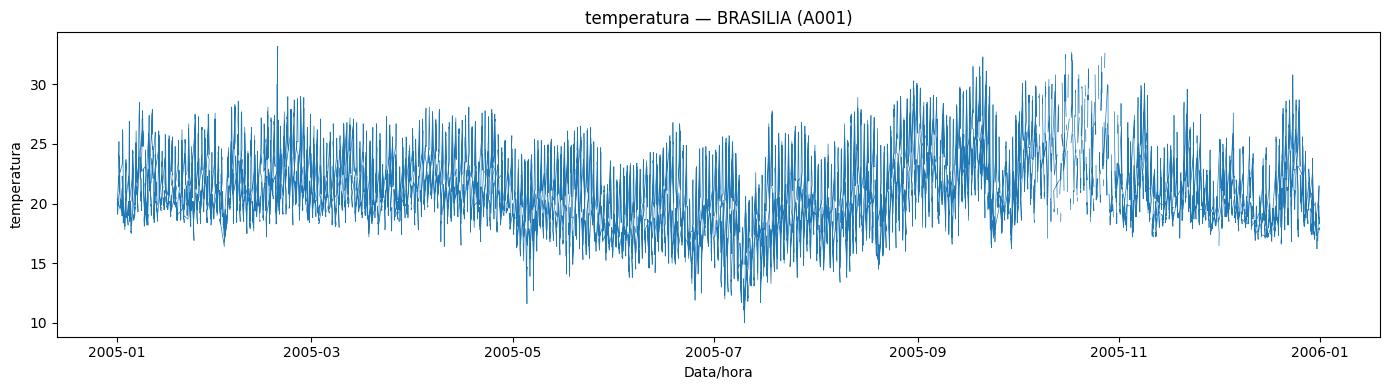

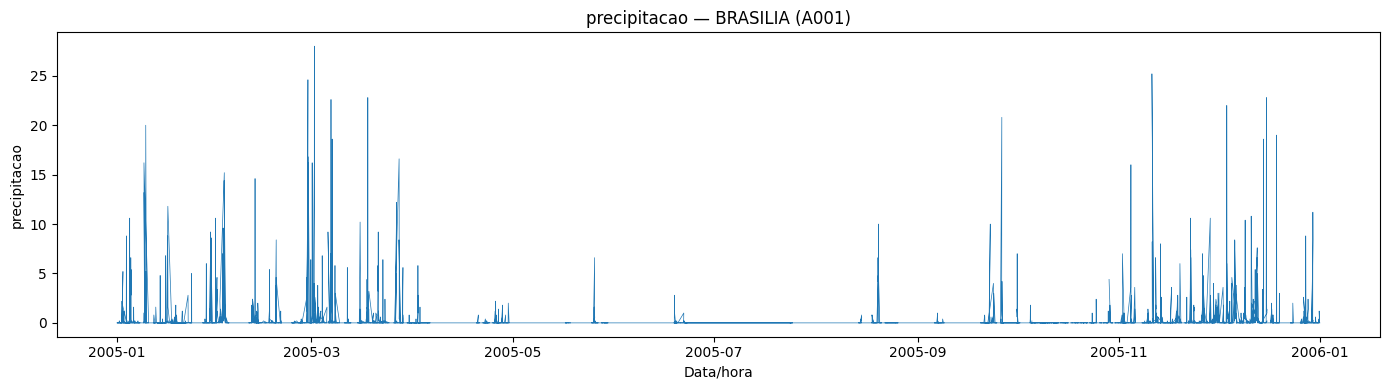

In [33]:
plotar_serie_horaria(arquivos[0], variavel='temperatura')
plotar_serie_horaria(arquivos[0], variavel='precipitacao')